In [ ]:
import pandas as pd
import numpy as np

# CSV File load karein
df = pd.read_csv('/food_delivery_data.csv')

# Top 5 rows dekhein
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Type_of_order,Type_of_vehicle,Time_taken(min)
0,6E6J,CHENRES56DEL18,38,4.6,24.789054,72.474514,24.820402,72.595530,Snack,motorcycle,34
1,AV7T,DELRES27DEL46,42,2.4,10.680204,85.157868,10.787073,85.191674,Drinks,electric_scooter,47
2,SXRQ,INDORES42DEL70,45,3.2,12.187933,80.308146,12.216412,80.360247,Meal,bicycle,41
3,TY2D,BANGRES39DEL60,33,4.6,17.796586,70.527471,17.823199,70.562988,Buffet,electric_scooter,36
4,9XXG,COIMBRES41DEL38,21,1.4,18.473374,81.683375,18.490304,81.754647,Buffet,electric_scooter,37


In [ ]:
# Distance calculate karne ke liye Haversine Formula
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371.0 # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    return R * c

# Naya 'distance_km' column banayein
df['distance_km'] = haversine_distance(
    df['Restaurant_latitude'], df['Restaurant_longitude'],
    df['Delivery_location_latitude'], df['Delivery_location_longitude']
)

# Output check karein
df[['distance_km', 'Time_taken(min)']].head()

,distance_km,Time_taken(min)
0,12.702487,34
1,12.443998,47
2,6.487878,41
3,4.784901,36
4,7.748544,37


/tmp/ipykernel_2240/4181146143.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Type_of_vehicle', y='Time_taken(min)', ci=None)


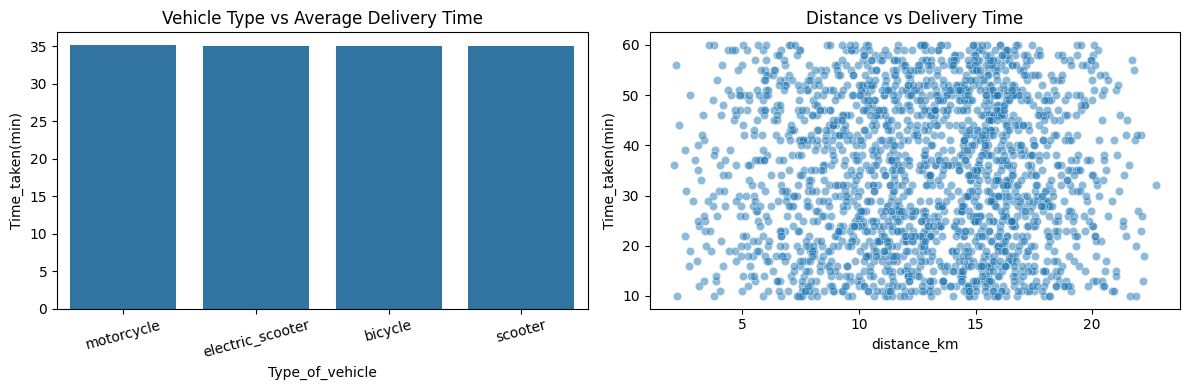

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 4))

# Chart 1: Vehicle vs Delivery Time
plt.subplot(1, 2, 1)
sns.barplot(data=df, x='Type_of_vehicle', y='Time_taken(min)', ci=None)
plt.title('Vehicle Type vs Average Delivery Time')
plt.xticks(rotation=15)

# Chart 2: Distance vs Delivery Time
plt.subplot(1, 2, 2)
sns.scatterplot(data=df.sample(2000), x='distance_km', y='Time_taken(min)', alpha=0.5)
plt.title('Distance vs Delivery Time')

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Unnecessary columns drop karein
drop_cols = ['ID', 'Delivery_person_ID', 'Restaurant_latitude',
             'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude']
df_ml = df.drop(columns=drop_cols)

# Text columns (Type_of_order, Type_of_vehicle) ko numbers me badlein (One-Hot Encoding)
df_ml = pd.get_dummies(df_ml, columns=['Type_of_order', 'Type_of_vehicle'], drop_first=True)

# Features (X) aur Target (y) split karein
X = df_ml.drop(columns=['Time_taken(min)'])
y = df_ml['Time_taken(min)']

# Data ko Train (80%) aur Test (20%) sets me split karein
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Data ML ke liye successfully split ho gaya!")
print("Training Data shape:", X_train.shape)
print("Testing Data shape:", X_test.shape)

Data ML ke liye successfully split ho gaya!
Training Data shape: (120000, 9)
Testing Data shape: (30000, 9)


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ML Model create karein
model = HistGradientBoostingRegressor(random_state=42)

print("Model train ho raha hai, thoda wait karein...")
model.fit(X_train, y_train)

# Test data par prediction karein
y_pred = model.predict(X_test)

# Model Performance check karein
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n--- Model Evaluation Results ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} minutes")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} minutes")
print(f"R2 Score: {r2:.2f}")

Model train ho raha hai, thoda wait karein...

--- Model Evaluation Results ---
Mean Absolute Error (MAE): 12.76 minutes
Root Mean Squared Error (RMSE): 14.72 minutes
R2 Score: -0.00


In [ ]:
# Naye order ki details (Example Input)
new_order = pd.DataFrame([{
    'Delivery_person_Age': 28,
    'Delivery_person_Ratings': 4.8,
    'distance_km': 6.5,
    'Type_of_order_Drinks': 0,
    'Type_of_order_Meal': 1,
    'Type_of_order_Snack': 0,
    'Type_of_vehicle_electric_scooter': 0,
    'Type_of_vehicle_motorcycle': 1,
    'Type_of_vehicle_scooter': 0
}])

# Training features ke sath columns match karein
new_order = new_order.reindex(columns=X_train.columns, fill_value=0)

# Delivery time predict karein
predicted_time = model.predict(new_order)[0]
print(f"Is order ke liye Estimated Delivery Time: {predicted_time:.1f} minutes")

Is order ke liye Estimated Delivery Time: 35.1 minutes


In [ ]:
import joblib

# Model ko save karein
joblib.dump(model, 'delivery_time_model.pkl')

print("Model successfully 'delivery_time_model.pkl' ke naam se save ho gaya hai!")

Model successfully 'delivery_time_model.pkl' ke naam se save ho gaya hai!
